# Data Visualisation: Environmental Trends and Risks

This notebook uses `global_climate_impact_1990_2025.csv` to communicate air-quality and climate indicators through clear, unit-labelled charts. The visualisations focus on long-term particulate trends, measurement coverage, recent geographic differences, emissions and temperature trends, and the relationship between PM2.5 and respiratory disease rates.

## How to interpret the charts
- Annual country averages are **equally weighted across available countries**, not weighted by population.
- Missing values are omitted from each chart and summary; measurement coverage is shown where relevant.
- Dashed PM2.5 (5 µg/m³) and PM10 (15 µg/m³) reference lines show the WHO 2021 annual guideline values. They are health-based guidelines, not a regulatory determination.
- CO₂ emissions totals and ambient pollutant concentrations are different measures.
- The respiratory-disease chart is descriptive; association does not establish causation or individual exposure.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

CSV_NAME = "global_climate_impact_1990_2025.csv"
data_path = next(
    (parent / CSV_NAME for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / CSV_NAME).is_file()),
    None,
)
if data_path is None:
    raise FileNotFoundError(
        f"Could not find {CSV_NAME!r} in the current directory or its parents."
    )

df = pd.read_csv(data_path)
required_columns = {
    "Country", "Continent", "Year", "PM2_5_Annual_Mean_ug_m3",
    "PM10_Annual_Mean_ug_m3", "CO2_Emissions_Total_Mt",
    "Temperature_Anomaly_C", "Respiratory_Disease_Rate_Per100k",
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"CSV is missing required columns: {sorted(missing_columns)}")

df["Year"] = pd.to_numeric(df["Year"], errors="raise").astype(int)
latest_year = int(df["Year"].max())
print(
    f"Loaded {len(df):,} country-year observations for "
    f"{df['Country'].nunique():,} countries ({df['Year'].min()}–{latest_year})."
)
plt.style.use("seaborn-v0_8-whitegrid")
COLORS = {"PM2.5": "#b23a48", "PM10": "#28666e", "CO2": "#4c956c", "climate": "#59656f"}
PM25_GUIDELINE = 5.0
PM10_GUIDELINE = 15.0

Loaded 6,948 country-year observations for 193 countries (1990–2025).


## 1. Particulate pollution trends and reporting coverage

The first figure pairs the annual mean concentration with the number of countries that reported a value. This helps distinguish changes in the measured mean from changes in coverage.

In [2]:
annual_pm = df.groupby("Year").agg(
    PM2_5_mean=("PM2_5_Annual_Mean_ug_m3", "mean"),
    PM2_5_n=("PM2_5_Annual_Mean_ug_m3", "count"),
    PM10_mean=("PM10_Annual_Mean_ug_m3", "mean"),
    PM10_n=("PM10_Annual_Mean_ug_m3", "count"),
)

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
axes[0].plot(annual_pm.index, annual_pm["PM2_5_mean"], color=COLORS["PM2.5"],
             linewidth=2, label="PM2.5")
axes[0].plot(annual_pm.index, annual_pm["PM10_mean"], color=COLORS["PM10"],
             linewidth=2, label="PM10")
axes[0].axhline(PM25_GUIDELINE, color=COLORS["PM2.5"], linestyle="--", alpha=0.7,
                label="WHO PM2.5 guideline: 5 µg/m³")
axes[0].axhline(PM10_GUIDELINE, color=COLORS["PM10"], linestyle="--", alpha=0.7,
                label="WHO PM10 guideline: 15 µg/m³")
axes[0].set(title="Annual mean particulate concentrations across reporting countries",
            ylabel="Concentration (µg/m³)")
axes[0].legend(frameon=False, ncol=2)
axes[1].plot(annual_pm.index, annual_pm["PM2_5_n"], color=COLORS["PM2.5"],
             label="PM2.5 reporting countries")
axes[1].plot(annual_pm.index, annual_pm["PM10_n"], color=COLORS["PM10"],
             label="PM10 reporting countries")
axes[1].set(xlabel="Year", ylabel="Countries with measurements",
            title="Measurement coverage")
axes[1].legend(frameon=False, ncol=2)
for ax in axes:
    ax.grid(alpha=0.25)
fig.suptitle("Particulate matter: trend and coverage", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

display(annual_pm.loc[[annual_pm.index.min(), annual_pm.index.max()]].round(2))

<Figure size 1200x900 with 2 Axes>

,PM2_5_mean,PM2_5_n,PM10_mean,PM10_n
Year,,,,
1990,24.70,124,39.34,113
2025,19.82,192,30.62,191


## 2. Recent PM2.5 differences by continent and country

Use the latest year in the file rather than assuming a fixed end year. The continent chart shows both its country-average level and the number of reporting countries; the country chart highlights the highest observed readings.

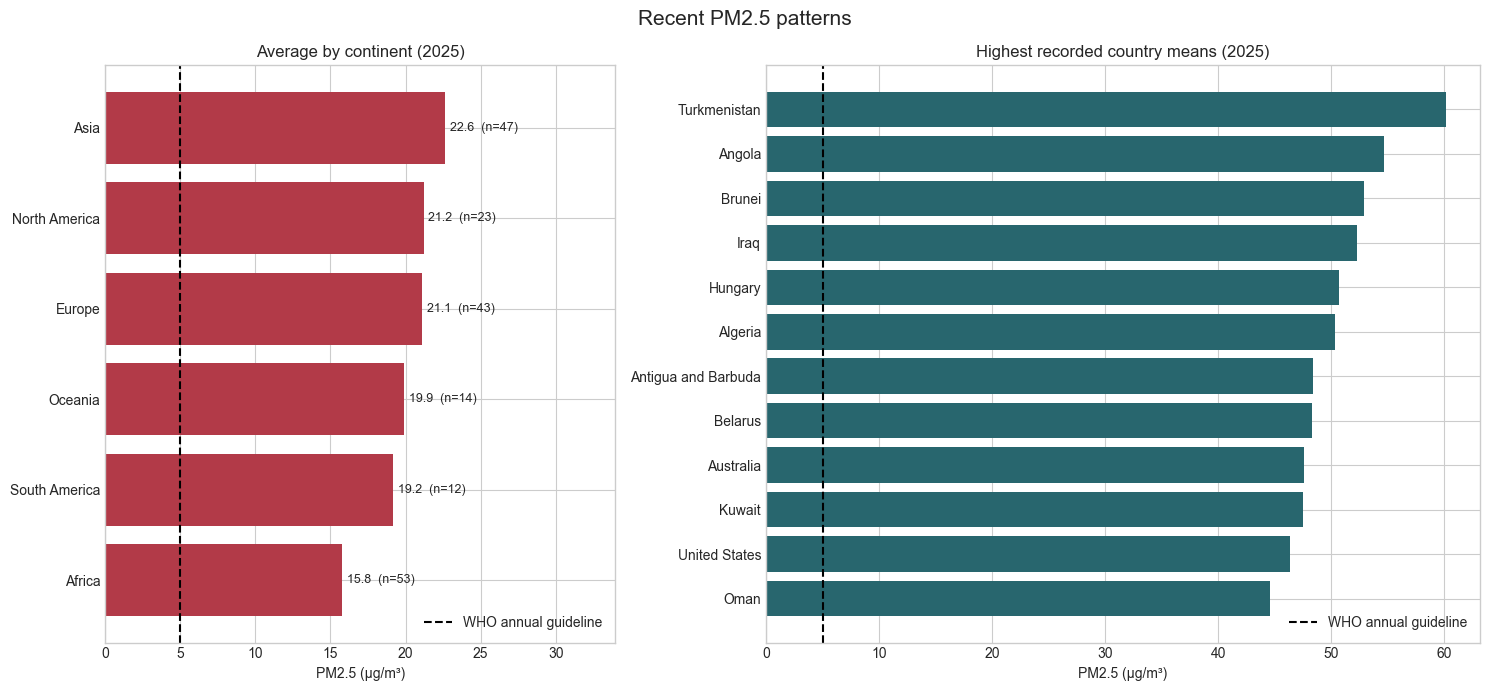

182/192 countries with observations (94.8%) were above the PM2.5 guideline in 2025. This is not a population exposure share.


In [3]:
latest = df.loc[df["Year"].eq(latest_year)].copy()
continent_pm = latest.groupby("Continent").agg(
    PM2_5_mean=("PM2_5_Annual_Mean_ug_m3", "mean"),
    countries=("PM2_5_Annual_Mean_ug_m3", "count"),
).dropna(subset=["PM2_5_mean"]).sort_values("PM2_5_mean")
top_countries = latest.nlargest(12, "PM2_5_Annual_Mean_ug_m3").sort_values(
    "PM2_5_Annual_Mean_ug_m3"
)

fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].barh(continent_pm.index, continent_pm["PM2_5_mean"], color=COLORS["PM2.5"])
axes[0].axvline(PM25_GUIDELINE, color="black", linestyle="--",
                label="WHO annual guideline")
for y, (value, n) in enumerate(zip(continent_pm["PM2_5_mean"], continent_pm["countries"])):
    axes[0].text(value + 0.3, y, f"{value:.1f}  (n={n})", va="center", fontsize=9)
axes[0].set(title=f"Average by continent ({latest_year})",
            xlabel="PM2.5 (µg/m³)", ylabel="")
axes[0].legend(frameon=False, loc="lower right")
axes[0].set_xlim(0, continent_pm["PM2_5_mean"].max() * 1.5)

axes[1].barh(top_countries["Country"], top_countries["PM2_5_Annual_Mean_ug_m3"],
             color=COLORS["PM10"])
axes[1].axvline(PM25_GUIDELINE, color="black", linestyle="--",
                label="WHO annual guideline")
axes[1].set(title=f"Highest recorded country means ({latest_year})",
            xlabel="PM2.5 (µg/m³)", ylabel="")
axes[1].legend(frameon=False, loc="lower right")
fig.suptitle("Recent PM2.5 patterns", fontsize=15)
plt.tight_layout()
plt.show()

observed_pm25 = latest["PM2_5_Annual_Mean_ug_m3"].dropna()
if not observed_pm25.empty:
    above_guideline = int(observed_pm25.gt(PM25_GUIDELINE).sum())
    print(
        f"{above_guideline}/{len(observed_pm25)} countries with observations "
        f"({observed_pm25.gt(PM25_GUIDELINE).mean() * 100:.1f}%) were above "
        f"the PM2.5 guideline in {latest_year}. This is not a population exposure share."
    )

## 3. Climate and emissions signals

Temperature anomaly and reported CO₂ emissions have different units and meanings, so they are plotted in separate panels. The emissions panel shows reporting counts because missing country totals can influence the sum.

C:\Users\amissetu\AppData\Local\Temp\ipykernel_760\1662586944.py:23: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  plt.tight_layout()
C:\Users\amissetu\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


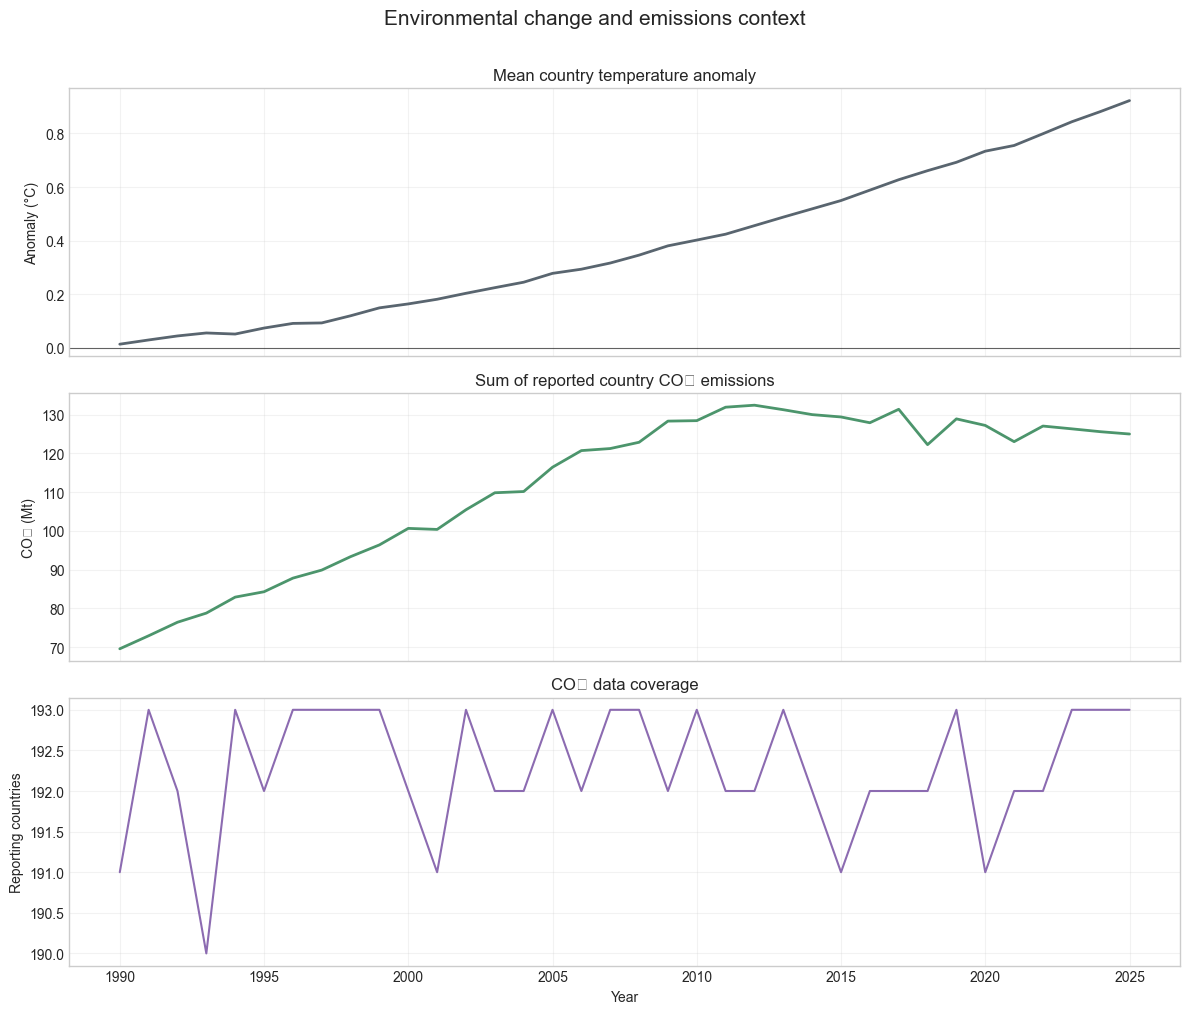

,temperature_anomaly,reported_CO2_Mt,CO2_reporting_countries
Year,,,
1990,0.01,69.60,191
2025,0.92,124.97,193


In [5]:
climate_annual = df.groupby("Year").agg(
    temperature_anomaly=("Temperature_Anomaly_C", "mean"),
    reported_CO2_Mt=("CO2_Emissions_Total_Mt", "sum"),
    CO2_reporting_countries=("CO2_Emissions_Total_Mt", "count"),
)
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
axes[0].plot(climate_annual.index, climate_annual["temperature_anomaly"],
             color=COLORS["climate"], linewidth=2)
axes[0].axhline(0, color="black", linewidth=0.8, alpha=0.6)
axes[0].set_ylabel("Anomaly (°C)")
axes[0].set_title("Mean country temperature anomaly")
axes[1].plot(climate_annual.index, climate_annual["reported_CO2_Mt"],
             color=COLORS["CO2"], linewidth=2)
axes[1].set_ylabel("CO₂ (Mt)")
axes[1].set_title("Sum of reported country CO₂ emissions")
axes[2].plot(climate_annual.index, climate_annual["CO2_reporting_countries"],
             color="#8c6bb1")
axes[2].set(xlabel="Year", ylabel="Reporting countries",
            title="CO₂ data coverage")
for ax in axes:
    ax.grid(alpha=0.25)
fig.suptitle("Environmental change and emissions context", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()
display(climate_annual.loc[[climate_annual.index.min(), climate_annual.index.max()]].round(2))

## 4. Geographic hotspot map by continent and year

This heatmap shows mean PM2.5 by continent and year. It is a compact way to compare broad regional patterns across time; cells with fewer reporting countries may be less representative.

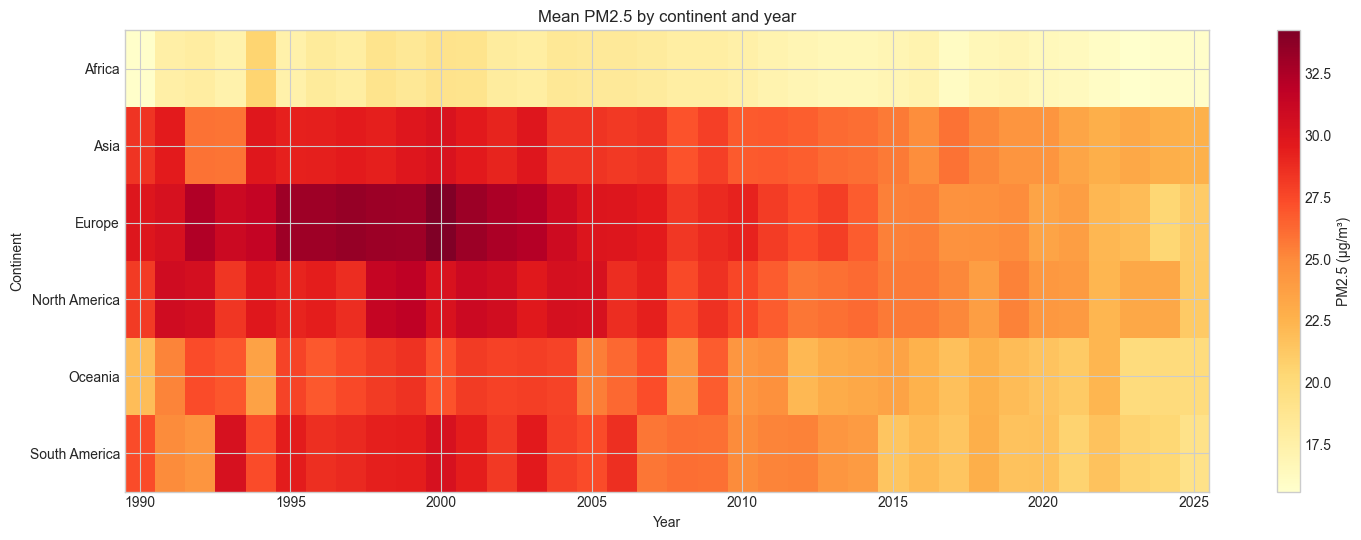

Countries contributing to each continent-year mean (selected years):


Year,1990,2000,2010,2020,2025
Continent,,,,,
Africa,34,53,52,53,53
Asia,29,48,48,48,47
Europe,30,42,43,43,43
North America,12,23,23,23,23
Oceania,9,13,14,14,14
South America,10,12,12,12,12


In [6]:
regional_yearly = df.pivot_table(
    index="Continent",
    columns="Year",
    values="PM2_5_Annual_Mean_ug_m3",
    aggfunc="mean",
)
coverage = df.pivot_table(
    index="Continent",
    columns="Year",
    values="PM2_5_Annual_Mean_ug_m3",
    aggfunc="count",
).reindex(index=regional_yearly.index, columns=regional_yearly.columns)
fig, ax = plt.subplots(figsize=(15, 5.5))
image = ax.imshow(regional_yearly, aspect="auto", cmap="YlOrRd", interpolation="nearest")
ax.set_yticks(np.arange(len(regional_yearly.index)), regional_yearly.index)
tick_positions = np.arange(0, len(regional_yearly.columns), 5)
ax.set_xticks(tick_positions, regional_yearly.columns[tick_positions])
ax.set(title="Mean PM2.5 by continent and year",
       xlabel="Year", ylabel="Continent")
colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("PM2.5 (µg/m³)")
plt.tight_layout()
plt.show()

print("Countries contributing to each continent-year mean (selected years):")
display(coverage.loc[:, coverage.columns.isin([1990, 2000, 2010, 2020, latest_year])])

## 5. Pollution and respiratory disease: descriptive association

A scatter plot reveals the distribution and possible association without hiding outliers behind a single summary statistic. The correlation is descriptive and may reflect shared trends or confounders.

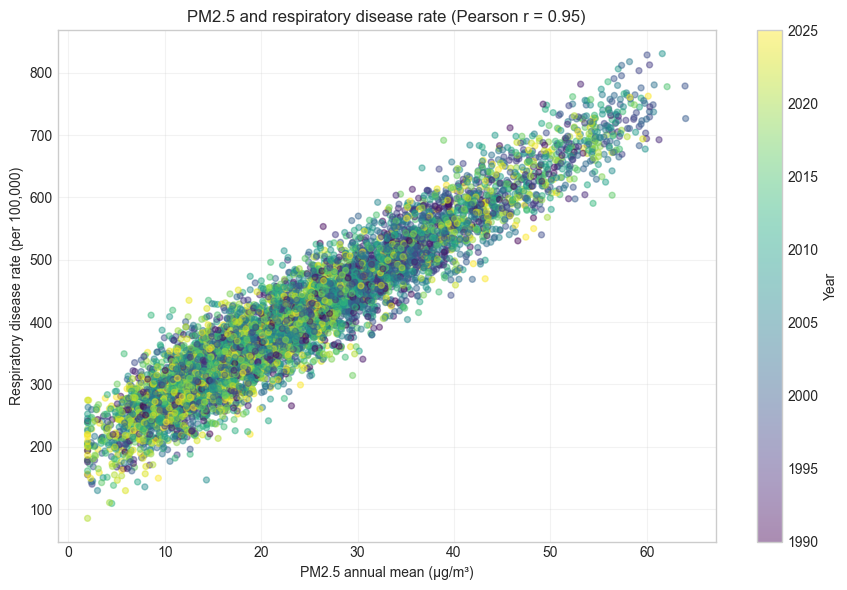

Paired country-year observations: 6,430


In [7]:
relationship = df[
    ["PM2_5_Annual_Mean_ug_m3", "Respiratory_Disease_Rate_Per100k"]
].dropna()
if len(relationship) >= 2:
    correlation = relationship.iloc[:, 0].corr(relationship.iloc[:, 1])
    fig, ax = plt.subplots(figsize=(9, 6))
    points = ax.scatter(
        relationship["PM2_5_Annual_Mean_ug_m3"],
        relationship["Respiratory_Disease_Rate_Per100k"],
        c=df.loc[relationship.index, "Year"],
        cmap="viridis",
        alpha=0.45,
        s=18,
    )
    fig.colorbar(points, ax=ax, label="Year")
    ax.set(title=f"PM2.5 and respiratory disease rate (Pearson r = {correlation:.2f})",
           xlabel="PM2.5 annual mean (µg/m³)",
           ylabel="Respiratory disease rate (per 100,000)")
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()
    print(f"Paired country-year observations: {len(relationship):,}")
else:
    print("Not enough paired measurements to visualize the relationship.")

## Communication takeaways

- Use paired trend and coverage plots to avoid overstating trends when reporting availability changes.
- Use continent comparisons and the heatmap to identify broad monitoring priorities, then investigate local data before taking action.
- Use distinct panels for emissions, concentrations, and temperature so units are not conflated.
- Read country-level exceedance counts as a data-screening indicator, not as the percentage of people exposed.
- Treat the health relationship as an exploratory association, not a causal conclusion.

**Recommended next step:** verify data provenance and indicator definitions, then pair station-level measurements with population estimates and uncertainty intervals for decision-ready communication.